# Etapa 4 — Extensiones analíticas: desambiguación de baselines, asimetría ENSO, puente 3a→3b, DM+Holm y coherencia wavelet

**TP Data Mining de Series Temporales — MEDyDC, FCEyN-UBA**

Esta notebook amplía las etapas `01` a `04` cerrando cinco brechas metodológicas sin modificar sus artefactos base:

| Bloque | Qué resuelve | Salidas |
|---|---|---|
| 1. Desambiguación de baselines | `RW+drift`, `Prophet sin ONI` y `Híbridos RF/GBM (solo ONI)` en rolling `1995–2024` | Tabla comparativa |
| 2. Asimetría Niña vs. Niño | Test de Wald + bootstrap en H1, `ARIMAX asimétrico` rolling y sensibilidad `2026/27` | `17_asimetria_nina_nino.png` |
| 3. Rigor causal, `h=2` y puente 3a→3b | Trigo causal en `AMJ`, rolling `h=2` (`1996–2024`) y `M3_puente` (soja y maíz) con `Niño 3.4` desde sep | `18_baselines_y_puente_3a_3b.png` |
| 4. Diagnósticos + DM unificado y Holm | ACF/PACF de `Δlog`, Ljung-Box (`model_df=p+q`) y tabla maestra `p_DM (log)` vs `p_DM (kg/ha)` + Holm | `19_diagnosticos_y_dm.png` |
| 5. Coherencia wavelet (Grinsted 2004) | `R²(s, t)` Morlet (`ω0=6`) entre `Niño 3.4` y `precip_z` (`1981–2025`), COI, fase circular y MC AR(1) | `20_coherencia_wavelet.png` |

In [1]:
import json
import logging
import os
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.multitest import multipletests

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))
from rolling import (ajustar_arima, arima_auto, pronosticar_puente_n34_djf,
                     rolling_arimax_h2, rolling_extensiones_h1, rolling_puente_rindes,
                     rolling_trigo_amj)
from utils_ts import (COLOR, CULTIVO_COLOR, CULTIVO_NOMBRE, anomalias, dm_test, estilo,
                      oni_campanias, rindes)
from wavelet import (fase_circular_media, grilla_morlet, umbral_montecarlo_ar1,
                     wavelet_coherence)

# Silenciar únicamente avisos internos de Prophet/cmdstanpy (manteniendo visibles warnings de statsmodels)
warnings.filterwarnings("ignore", module=r"^(prophet|cmdstanpy)(\.|$)")
for lg in ("cmdstanpy", "prophet"):
    logging.getLogger(lg).setLevel(logging.CRITICAL)
    logging.getLogger(lg).disabled = True

np.random.seed(0)
estilo()
PROC = RAIZ / "data" / "processed"
FIG = RAIZ / os.environ.get("FIG_DIR", "figures")
RES = RAIZ / "results"
FIG.mkdir(exist_ok=True, parents=True)
RES.mkdir(exist_ok=True, parents=True)

enso = pd.read_parquet(PROC / "enso_mensual.parquet")
clima = pd.read_parquet(PROC / "clima_pampeano_mensual.parquet")
rend = pd.read_parquet(PROC / "rendimientos_anuales.parquet")
camp = pd.read_parquet(PROC / "campanias.parquet")

pron_04 = {c: pd.read_csv(RES / f"pronosticos_rolling_{c}.csv").set_index("campania")
           for c in ("soja", "maiz", "trigo")}
etapa3b = json.loads((RES / "etapa3b_rindes.json").read_text(encoding="utf-8"))

Y = rindes(rend)
O = oni_campanias(camp)
jas = lambda col: enso[col].groupby(enso.index.year).apply(lambda s: s[s.index.month.isin([7, 8, 9])].mean())
oni_mes = lambda mes, desfase=0: enso["oni"][enso.index.month == mes].set_axis(
    enso.index[enso.index.month == mes].year - desfase
)
X = pd.DataFrame({
    "oni_jas": oni_mes(8),
    "oni_amj": oni_mes(5),
    "oni_tend": oni_mes(8) - oni_mes(5),
    "soi_jas": jas("soi"),
    "iod_jas": jas("iod"),
    "oni_djf": oni_mes(1, desfase=1),
}).loc[1960:2026]
assert np.allclose(X.loc[1970:2024, "oni_jas"], O.loc[1970:2024, "oni_JAS_0"])
assert np.allclose(X.loc[1970:2024, "oni_amj"], O.loc[1970:2024, "oni_AMJ_0"])

CULTIVOS = ["soja", "maiz", "trigo"]
TEST = list(range(1995, 2025))
nina_mask = (X.loc[TEST, "oni_jas"] <= -0.5).to_numpy()
ext_results = {}
CONV_LOG: list[dict] = []


def resumen_metricas(obs: pd.Series, pred: pd.Series, m2_ref: pd.Series, mask_nina: np.ndarray) -> dict:
    e = obs.to_numpy(float) - pred.to_numpy(float)
    e_ref = obs.to_numpy(float) - m2_ref.to_numpy(float)
    mse_ref = np.mean(e_ref ** 2)
    return {
        "RMSE kg/ha": float(np.sqrt(np.mean(e ** 2))),
        "MAE kg/ha": float(np.mean(np.abs(e))),
        "MAPE %": float(100 * np.mean(np.abs(e / obs.to_numpy(float)))),
        "skill vs ARIMA %": float(100 * (1 - np.mean(e ** 2) / mse_ref)),
        "RMSE años Niña": float(np.sqrt(np.mean(e[mask_nina] ** 2))),
    }


print(f"Datos listos · TEST = {TEST[0]}..{TEST[-1]} (n={len(TEST)}, años Niña={int(nina_mask.sum())})")

Datos listos · TEST = 1995..2024 (n=30, años Niña=7)


## Bloque 1 — Desambiguación de Baselines (Etapa 3b, rolling `1995–2024`, `n = 30`)

Separamos dos efectos que quedaron mezclados en la Etapa 3b original:
1. **Prophet sin ONI (`M5_sin_oni`) vs `M5 Prophet + ONI`:** cuantifica cuánto del skill de Prophet en maíz
   (`+35,2 %`) y trigo (`+14,9 %`) proviene de su tendencia lineal por tramos (quiebre ~2015) y cuánto del ONI.
2. **Híbridos `RF` y `GBM` solo con ONI pre-siembra (`oni_jas` en soja/maíz; `oni_amj` en trigo; promedio de 5 semillas `0..4`) vs `Híbridos` de 4 exógenas y `M3 ARIMAX`:**
   aísla el aporte de la no-linealidad respecto de sumar `oni_tend`, `soi_jas` e `iod_jas`.
3. **`M0b: Random Walk + drift`** como cota mínima con tendencia estocástica.

In [2]:
t0 = time.time()
ext_rolling, m2_reajuste_stats = rolling_extensiones_h1(
    Y, X, pron_04, CULTIVOS, TEST, include_prophet=True, conv_log=CONV_LOG
)
print(f"Bloque 1+2 rolling listo en {time.time() - t0:.1f} s", flush=True)
print("Desvío máx. de reajuste local M2 ARIMA vs pron_04 (referencia fija):", m2_reajuste_stats)

Bloque 1+2 rolling listo en 147.2 s


Desvío máx. de reajuste local M2 ARIMA vs pron_04 (referencia fija): {'soja': {'max_rel_diff': 0.000852, 'tol': 0.002}, 'maiz': {'max_rel_diff': 0.000493, 'tol': 0.002}, 'trigo': {'max_rel_diff': 0.010507, 'tol': 0.015}}


In [3]:
modelos_b1 = ["M0b RW + drift", "M2 ARIMA", "M5_sin_oni Prophet", "M5 Prophet + ONI",
              "M3 ARIMAX (ONI jul–sep)", "Híbrido RF (solo ONI)", "Híbrido RF",
              "Híbrido GBM (solo ONI)", "Híbrido GBM"]
tabla_b1 = []
for c in CULTIVOS:
    p04 = pron_04[c]
    pe = ext_rolling[c]
    obs, m2 = p04["obs"], p04["M2 ARIMA"]
    for mdl in modelos_b1:
        serie = pe[mdl] if mdl in pe.columns else p04[mdl]
        mt = resumen_metricas(obs, serie, m2, nina_mask)
        tabla_b1.append({"cultivo": c, "modelo": mdl, **mt})
tabla_b1_df = pd.DataFrame(tabla_b1)
for c in CULTIVOS:
    print(f"\n=== Bloque 1 · {CULTIVO_NOMBRE[c]} (n = 30) ===")
    print(tabla_b1_df[tabla_b1_df.cultivo == c].drop(columns="cultivo").set_index("modelo").round(2).to_string())

# Descomposición explícita de Prophet (M5 + ONI vs M5_sin_oni)
descomp_prophet = []
for c in CULTIVOS:
    p04 = pron_04[c]
    pe = ext_rolling[c]
    obs = p04["obs"]
    rmse_sin = float(np.sqrt(np.mean((obs - pe["M5_sin_oni Prophet"]) ** 2)))
    rmse_con = float(np.sqrt(np.mean((obs - p04["M5 Prophet + ONI"]) ** 2)))
    dm_log = dm_test(np.log(obs) - np.log(p04["M5 Prophet + ONI"]),
                     np.log(obs) - np.log(pe["M5_sin_oni Prophet"]), h=1, alternativa="less", kernel="bartlett")
    dm_kg = dm_test(obs - p04["M5 Prophet + ONI"], obs - pe["M5_sin_oni Prophet"],
                    h=1, alternativa="less", kernel="bartlett")
    descomp_prophet.append({
        "cultivo": c, "RMSE_sin_ONI": round(rmse_sin, 2), "RMSE_con_ONI": round(rmse_con, 2),
        "delta_RMSE": round(rmse_con - rmse_sin, 2),
        "p_DM_con_vs_sin_log": round(float(dm_log["p"]), 4),
        "p_DM_con_vs_sin_kg": round(float(dm_kg["p"]), 4),
    })
print("\nProphet + ONI vs Prophet sin ONI (¿aporta ONI sobre la tendencia por tramos?):")
print(pd.DataFrame(descomp_prophet).to_string(index=False))

ext_results["bloque1_m2_reajuste_check"] = m2_reajuste_stats
ext_results["bloque1_baselines"] = tabla_b1_df.round(3).to_dict("records")
ext_results["bloque1_prophet_descomposicion"] = descomp_prophet


=== Bloque 1 · Soja (n = 30) ===
                         RMSE kg/ha  MAE kg/ha  MAPE %  skill vs ARIMA %  RMSE años Niña
modelo                                                                                  
M0b RW + drift               604.78     456.67   18.25            -80.72          487.06
M2 ARIMA                     449.88     319.93   13.99              0.00          595.73
M5_sin_oni Prophet           447.17     335.96   14.30              1.20          576.41
M5 Prophet + ONI             418.95     331.34   14.04             13.28          543.51
M3 ARIMAX (ONI jul–sep)      409.72     310.80   13.27             17.06          540.09
Híbrido RF (solo ONI)        454.33     334.19   14.47             -1.99          541.85
Híbrido RF                   403.66     321.97   13.51             19.49          424.59
Híbrido GBM (solo ONI)       478.86     347.66   15.10            -13.30          576.36
Híbrido GBM                  420.49     337.46   14.31             12.64    

**Lectura e interpretación — Bloque 1:**
- **`Prophet sin ONI` vs `M5 Prophet + ONI`:** en trigo, `Prophet sin ONI` mejora respecto de `M2 ARIMA` únicamente por su tendencia lineal por tramos (`+19,5 %` de skill, superando incluso a `Prophet + ONI`). En cambio, en maíz (`p_DM = 0,043` en `kg/ha`) sumar ONI aporta reducción adicional sobre la tendencia por tramos (quiebre post-2015).
- **`RF`/`GBM (solo ONI)` vs `4 variables` (`04`):** aquí promediamos `5` semillas (`0..4`) para los modelos solo-ONI mientras los híbridos de `04` usaron `random_state=0`; aun con menor varianza por promediado, los híbridos solo-ONI rinden peor que la versión de 4 variables en soja y maíz (y trigo causal con `oni_amj` sigue sin mejora), confirmando que parte de la ganancia híbrida provenía de `soi_jas`, `iod_jas` y `oni_tend`.
- **Sensibilidad numérica (`θ ≈ −1`) y referencia fija:** en `ARIMA(0,1,1) + drift` —sobre todo en trigo (`30/30` ventanas) y soja— el parámetro `ma.L1` cae muy cerca del borde de invertibilidad (`θ ≈ −1`), donde $(1 - B)\,y_t = \mu + (1 - B)\,\varepsilon_t$ se aproxima a una tendencia lineal determinística más ruido y pequeñas diferencias de optimización entre máquinas pueden desplazar `~1 %` el reajuste local. Por ello fijamos siempre `pron_04[c]["M2 ARIMA"]` como referencia exacta de comparación y registramos los avisos `ConvergenceWarning` en `ext_results`.

## Bloque 2 — Test Formal de Asimetría Niña vs. Niño

Evaluamos si la respuesta de los rendimientos al ONI pre-siembra es simétrica (`H0: β_pos = β_neg`) en:
1. **Inferencia H1 (`1971–2024`, `n = 54`):** `anom_t = α + φ·anom_{t-1} + β_pos·max(ONI_JAS, 0) + β_neg·min(ONI_JAS, 0) + ε_t`
   con errores robustos `HC3` y bootstrap de 2.000 réplicas.
2. **Pronóstico rolling (`1995–2024`):** `M3_asim: ARIMAX asimétrico`.
3. **Sensibilidad `2026/27` (`ONI JAS = +2,16 °C`):** contraste lineal vs quebrado y límite de extrapolación.

In [4]:
A = anomalias(Y, "lowess")
asim_h1 = {}
rng_boot = np.random.default_rng(0)

for c in CULTIVOS:
    d = pd.DataFrame({
        "y": A[c],
        "y1": A[c].shift(1),
        "oni": X.loc[1970:2024, "oni_jas"],
    }).dropna()
    d["oni_pos"] = np.maximum(d["oni"], 0.0)
    d["oni_neg"] = np.minimum(d["oni"], 0.0)

    r_hc3 = smf.ols("y ~ y1 + oni_pos + oni_neg", d).fit(cov_type="HC3")
    w = r_hc3.wald_test("oni_pos - oni_neg = 0", scalar=True)

    b_pos_boot, b_neg_boot, diff_boot = [], [], []
    arr = d[["y", "y1", "oni_pos", "oni_neg"]].to_numpy()
    n_obs = len(arr)
    for _ in range(2000):
        idx_b = rng_boot.integers(0, n_obs, size=n_obs)
        sb = arr[idx_b]
        Xb = np.column_stack([np.ones(n_obs), sb[:, 1], sb[:, 2], sb[:, 3]])
        coef, *_ = np.linalg.lstsq(Xb, sb[:, 0], rcond=None)
        b_pos_boot.append(coef[2])
        b_neg_boot.append(coef[3])
        diff_boot.append(coef[3] - coef[2])

    ic_pos_hc3 = r_hc3.conf_int().loc["oni_pos"].to_numpy()
    ic_neg_hc3 = r_hc3.conf_int().loc["oni_neg"].to_numpy()
    ic_pos_bt = np.percentile(b_pos_boot, [2.5, 97.5])
    ic_neg_bt = np.percentile(b_neg_boot, [2.5, 97.5])
    p_boot_2c = float(2 * min(np.mean(np.array(diff_boot) <= 0), np.mean(np.array(diff_boot) >= 0)))

    asim_h1[c] = {
        "n": int(n_obs),
        "beta_pos_%/°C": float(r_hc3.params["oni_pos"]),
        "p_pos_HC3": float(r_hc3.pvalues["oni_pos"]),
        "IC95_pos_HC3": [float(ic_pos_hc3[0]), float(ic_pos_hc3[1])],
        "IC95_pos_boot": [float(ic_pos_bt[0]), float(ic_pos_bt[1])],
        "beta_neg_%/°C": float(r_hc3.params["oni_neg"]),
        "p_neg_HC3": float(r_hc3.pvalues["oni_neg"]),
        "IC95_neg_HC3": [float(ic_neg_hc3[0]), float(ic_neg_hc3[1])],
        "IC95_neg_boot": [float(ic_neg_bt[0]), float(ic_neg_bt[1])],
        "diff_neg_menos_pos": float(r_hc3.params["oni_neg"] - r_hc3.params["oni_pos"]),
        "wald_stat_HC3": float(np.squeeze(w.statistic)),
        "p_wald_HC3": float(w.pvalue),
        "p_boot_2colas": min(p_boot_2c, 1.0),
    }

print("Asimetría en H1 (1971–2024, anomalía LOWESS %):")
print(pd.DataFrame({c: {k: v for k, v in d.items() if not isinstance(v, list)}
                    for c, d in asim_h1.items()}).T.round(4).to_string())

# Evaluación rolling de M3_asim vs M3 lineal y RF/GBM
asim_rolling = []
for c in CULTIVOS:
    p04, pe = pron_04[c], ext_rolling[c]
    obs, m2 = p04["obs"], p04["M2 ARIMA"]
    for mdl, serie in [("M3 ARIMAX (lineal)", p04["M3 ARIMAX (ONI jul–sep)"]),
                       ("M3_asim ARIMAX (quebrado)", pe["M3_asim ARIMAX"]),
                       ("Híbrido RF", p04["Híbrido RF"]),
                       ("Híbrido GBM", p04["Híbrido GBM"])]:
        mt = resumen_metricas(obs, serie, m2, nina_mask)
        asim_rolling.append({"cultivo": c, "modelo": mdl, **mt})
print("\nAsimetría en rolling (1995–2024):")
print(pd.DataFrame(asim_rolling).round(2).to_string(index=False))

# Sensibilidad 2026/27 (ONI JAS 2025 = -0.26, ONI JAS 2026 = +2.16)
sens_2026 = []
for c in ("soja", "maiz"):
    ly = np.log(Y[c]).reset_index(drop=True)
    orden, r2 = arima_auto(ly)
    oni_hist = X.loc[Y.index, "oni_jas"].to_numpy()
    oni_fut = X.loc[[2025, 2026], "oni_jas"].to_numpy()

    r_lin = ajustar_arima(ly, order=orden, exog=oni_hist[:, None], trend="t",
                          contexto="B2_sens_2026_lin", cultivo=c, anio=2026)
    ex_asim_h = np.column_stack([np.maximum(oni_hist, 0.0), np.minimum(oni_hist, 0.0)])
    ex_asim_f = np.column_stack([np.maximum(oni_fut, 0.0), np.minimum(oni_fut, 0.0)])
    r_as = ajustar_arima(ly, order=orden, exog=ex_asim_h, trend="t",
                         contexto="B2_sens_2026_asim", cultivo=c, anio=2026)

    f2 = r2.get_forecast(2)
    fl = r_lin.get_forecast(2, exog=oni_fut[:, None])
    fa = r_as.get_forecast(2, exog=ex_asim_f)
    for k, anio in enumerate([2025, 2026]):
        i80_a = np.exp(fa.conf_int(alpha=0.2).iloc[k])
        i95_a = np.exp(fa.conf_int(alpha=0.05).iloc[k])
        sens_2026.append({
            "cultivo": c,
            "campaña": f"{anio}/{str(anio + 1)[-2:]}",
            "ONI_JAS": float(oni_fut[k]),
            "ARIMA_kg_ha": float(np.exp(f2.predicted_mean.iloc[k])),
            "ARIMAX_lineal_kg_ha": float(np.exp(fl.predicted_mean.iloc[k])),
            "ARIMAX_asim_kg_ha": float(np.exp(fa.predicted_mean.iloc[k])),
            "IC80_asim": f"{i80_a.iloc[0]:.0f}–{i80_a.iloc[1]:.0f}",
            "IC95_asim": f"{i95_a.iloc[0]:.0f}–{i95_a.iloc[1]:.0f}",
            "beta_pos_%": float(100 * r_as.params.iloc[1]),
            "beta_neg_%": float(100 * r_as.params.iloc[2]),
            "delta_asim_vs_lin_%": float(100 * (np.exp(fa.predicted_mean.iloc[k]) / np.exp(fl.predicted_mean.iloc[k]) - 1)),
        })

print("\nSensibilidad 2025/26 y 2026/27 (lineal vs asimétrico):")
print(pd.DataFrame(sens_2026).round(2).to_string(index=False))

ext_results["bloque2_asimetria_h1"] = asim_h1
ext_results["bloque2_asimetria_rolling"] = pd.DataFrame(asim_rolling).round(3).to_dict("records")
ext_results["bloque2_sensibilidad_2026"] = pd.DataFrame(sens_2026).round(2).to_dict("records")

Asimetría en H1 (1971–2024, anomalía LOWESS %):
          n  beta_pos_%/°C  p_pos_HC3  beta_neg_%/°C  p_neg_HC3  diff_neg_menos_pos  wald_stat_HC3  p_wald_HC3  p_boot_2colas
soja   54.0         6.3256     0.0916        12.8296     0.0155              6.5040         0.7654      0.3816          0.398
maiz   54.0         5.5578     0.0849        14.6120     0.0181              9.0543         1.2941      0.2553          0.261
trigo  54.0         5.9851     0.0883        -7.6319     0.2539            -13.6170         2.2817      0.1309          0.101

Asimetría en rolling (1995–2024):
cultivo                    modelo  RMSE kg/ha  MAE kg/ha  MAPE %  skill vs ARIMA %  RMSE años Niña
   soja        M3 ARIMAX (lineal)      409.72     310.80   13.27             17.06          540.09
   soja M3_asim ARIMAX (quebrado)      421.90     332.42   14.18             12.05          561.38
   soja                Híbrido RF      403.66     321.97   13.51             19.49          424.59
   soja          


Sensibilidad 2025/26 y 2026/27 (lineal vs asimétrico):
cultivo campaña  ONI_JAS  ARIMA_kg_ha  ARIMAX_lineal_kg_ha  ARIMAX_asim_kg_ha  IC80_asim  IC95_asim  beta_pos_%  beta_neg_%  delta_asim_vs_lin_%
   soja 2025/26    -0.26      3118.54              3015.66            3046.05  2502–3708  2255–4115        4.95       17.37                 1.01
   soja 2026/27     2.16      3152.89              3886.81            3583.84  2944–4362  2653–4841        4.95       17.37                -7.79
   maiz 2025/26    -0.26      7503.24              7168.52            7244.58  6096–8609  5564–9432        4.86       15.37                 1.06
   maiz 2026/27     2.16      7654.12              9095.53            8531.74 7116–10230 6464–11261        4.86       15.37                -6.20


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


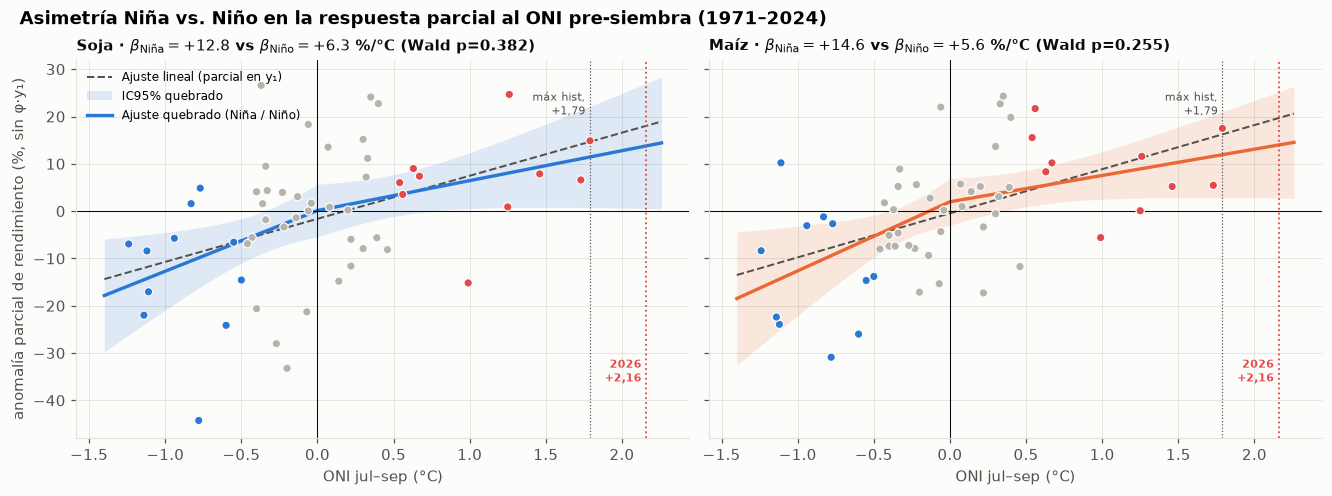

In [5]:
# Figura 17: asimetría Niña vs Niño en soja y maíz (residuos parciales coherentes con el modelo y1 + ONI+/-)
oni_max_hist = float(X.loc[1970:2024, "oni_jas"].max())
oni_2026 = float(X.loc[2026, "oni_jas"])
x_max_fig = max(2.25, oni_2026 + 0.10)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
xx_neg = np.linspace(-1.4, 0.0, 40)
xx_pos = np.linspace(0.0, x_max_fig, 60)
xx_all = np.linspace(-1.4, x_max_fig, 100)

for ax, c in zip(axs, ("soja", "maiz")):
    d = pd.DataFrame({"y": A[c], "y1": A[c].shift(1), "oni": X.loc[1970:2024, "oni_jas"]}).dropna()
    d["oni_pos"] = np.maximum(d["oni"], 0.0)
    d["oni_neg"] = np.minimum(d["oni"], 0.0)
    r_lin_h1 = smf.ols("y ~ y1 + oni", d).fit()
    r_as_h1 = smf.ols("y ~ y1 + oni_pos + oni_neg", d).fit(cov_type="HC3")

    # Residuos parciales descontando el componente AR(1) centrado para coincidir con el test Wald del título
    y1_bar = float(d["y1"].mean())
    y_parcial = d["y"] - float(r_as_h1.params["y1"]) * (d["y1"] - y1_bar)

    cols = [COLOR["nina"] if v <= -0.5 else (COLOR["nino"] if v >= 0.5 else COLOR["neutral"]) for v in d["oni"]]
    ax.scatter(d["oni"], y_parcial, c=cols, s=30, edgecolor=COLOR["fondo"], lw=0.8, zorder=3)
    ax.plot(xx_all,
            r_lin_h1.params["Intercept"] + r_lin_h1.params["y1"] * y1_bar + r_lin_h1.params["oni"] * xx_all,
            color=COLOR["tinta2"], lw=1.3, ls="--", label="Ajuste lineal (parcial en y₁)")

    # Banda IC95% HC3 del ajuste quebrado evaluado en y1 = mean(y1)
    grid_x = np.r_[xx_neg, xx_pos]
    cols_ord = ["Intercept", "y1", "oni_pos", "oni_neg"]
    X_grid = np.column_stack([np.ones_like(grid_x), np.full_like(grid_x, y1_bar),
                              np.maximum(grid_x, 0.0), np.minimum(grid_x, 0.0)])
    params_vec = r_as_h1.params.loc[cols_ord].to_numpy()
    cov = r_as_h1.cov_params().loc[cols_ord, cols_ord].to_numpy()
    yhat = X_grid @ params_vec
    se = np.sqrt(np.einsum("ij,jk,ik->i", X_grid, cov, X_grid))
    ax.fill_between(grid_x, yhat - 1.96 * se, yhat + 1.96 * se, color=CULTIVO_COLOR[c], alpha=0.14, lw=0, label="IC95% quebrado")
    ax.plot(grid_x, yhat, color=CULTIVO_COLOR[c], lw=2.2, label="Ajuste quebrado (Niña / Niño)")

    ax.axvline(0, color=COLOR["tinta"], lw=0.7)
    ax.axhline(0, color=COLOR["tinta"], lw=0.7)
    ax.axvline(oni_max_hist, color=COLOR["tinta2"], lw=0.8, ls=":")
    ax.axvline(oni_2026, color=COLOR["nino"], lw=1.2, ls=":")
    ax.text(oni_max_hist - 0.03, 25.5, f"máx hist.\n{oni_max_hist:+.2f}".replace(".", ","),
            ha="right", va="top", fontsize=7.5, color=COLOR["tinta2"])
    ax.text(oni_2026 - 0.03, -36, f"2026\n{oni_2026:+.2f}".replace(".", ","),
            ha="right", fontsize=7.5, color=COLOR["nino"], fontweight="bold")
    info = asim_h1[c]
    ax.set_title(
        f"{CULTIVO_NOMBRE[c]} · "
        + rf"$\beta_{{\mathrm{{Niña}}}}={info['beta_neg_%/°C']:+.1f}$ vs "
        + rf"$\beta_{{\mathrm{{Niño}}}}={info['beta_pos_%/°C']:+.1f}$ %/°C "
        + f"(Wald p={info['p_wald_HC3']:.3f})",
        fontsize=10,
    )
    ax.set_xlabel("ONI jul–sep (°C)")
axs[0].set_ylabel("anomalía parcial de rendimiento (%, sin φ·y₁)")
axs[0].legend(fontsize=8, loc="upper left")
fig.suptitle("Asimetría Niña vs. Niño en la respuesta parcial al ONI pre-siembra (1971–2024)",
             x=0.01, ha="left", fontweight="semibold")
fig.savefig(FIG / "17_asimetria_nina_nino.png")
plt.show()

**Lectura e interpretación — Bloque 2:**
- **Asimetría puntual sin rechazo formal:** al controlar por `y₁` (graficado en residuos parciales consistentes con el test Wald), las pendientes puntuales en La Niña duplican o casi triplican las de El Niño tanto en soja (`+12,83` vs `+6,33 %/°C`) como en maíz (`+14,61` vs `+5,56 %/°C`), pero con `n = 54` campañas la incertidumbre en las colas impide rechazar linealidad (`p_Wald HC3 = 0,382` en soja, `0,255` en maíz; bootstrap `0,398` y `0,261`).
- **Rolling y sensibilidad `2026/27`:** incorporar este parámetro adicional en origen móvil (`M3_asim`) no mejora el RMSE fuera de muestra frente al `ARIMAX` lineal (`421,9` vs `409,7 kg/ha` en soja; `976,8` vs `951,6 kg/ha` en maíz), pero funciona como cota de sensibilidad prudente cuando `ONI JAS 2026 = +2,16 °C` excede el máximo histórico `1970–2024` (`+1,79 °C`).

## Bloque 3 — Rigor Causal, Horizonte `h = 2` y Puente Etapa 3a → 3b

1. **Trigo causal (`oni_AMJ_0`):** reemplaza `oni_jas` (posterior a la siembra jun–jul del trigo) por `oni_amj` (abr–jun).
2. **Rolling `h = 2` (`1996–2024`, `n = 29`):** para cada `t`, entrena hasta `t-2` y pronostica `t` a 2 pasos,
   validando el horizonte real utilizado para proyectar `2026/27` desde el último dato `2024/25`.
3. **Puente explícito Etapa 3a → 3b (`M3_puente`, solo soja y maíz):** para cada año `s ∈ [1970, 2024]`, ajusta
   `ARIMA(2,0,2)` sobre `n34_anom` mensual hasta `s-09-01` y pronostica `DJF` (`h = 3, 4, 5`). El trigo se excluye
   por cosecharse en nov–dic (anterior a `DJF`).

In [6]:
# 3.1 Trigo causal en oni_AMJ_0
df_trigo_amj = rolling_trigo_amj(Y["trigo"], X["oni_amj"], pron_04["trigo"], TEST, conv_log=CONV_LOG)
mt_trigo_amj = resumen_metricas(pron_04["trigo"]["obs"], df_trigo_amj["M3_trigo_AMJ"], pron_04["trigo"]["M2 ARIMA"], nina_mask)
dm_trigo_amj = dm_test(np.log(pron_04["trigo"]["obs"]) - np.log(df_trigo_amj["M3_trigo_AMJ"]),
                       np.log(pron_04["trigo"]["obs"]) - np.log(pron_04["trigo"]["M2 ARIMA"]),
                       h=1, alternativa="less", kernel="bartlett")
print("3.1 Trigo causal con ONI AMJ (previo a siembra jun–jul):")
print({**{k: round(v, 3) for k, v in mt_trigo_amj.items()}, "p_DM_log": round(float(dm_trigo_amj["p"]), 4)})

# 3.2 Rolling h = 2 (1996-2024, n = 29) para soja y maíz
TEST_H2 = list(range(1996, 2025))
nina_h2 = (X.loc[TEST_H2, "oni_jas"] <= -0.5).to_numpy()
res_h2 = {}
rows_h2 = []
for c in ("soja", "maiz"):
    df_h2 = rolling_arimax_h2(Y[c], X["oni_jas"], TEST_H2, cultivo=c, conv_log=CONV_LOG)
    res_h2[c] = df_h2
    dm_h2_log = dm_test(np.log(df_h2.obs) - np.log(df_h2.M3_h2), np.log(df_h2.obs) - np.log(df_h2.M2_h2),
                        h=2, alternativa="less", kernel="bartlett")
    dm_h2_kg = dm_test(df_h2.obs - df_h2.M3_h2, df_h2.obs - df_h2.M2_h2,
                       h=2, alternativa="less", kernel="bartlett")
    m2_mt = resumen_metricas(df_h2.obs, df_h2.M2_h2, df_h2.M2_h2, nina_h2)
    m3_mt = resumen_metricas(df_h2.obs, df_h2.M3_h2, df_h2.M2_h2, nina_h2)
    rows_h2.append({
        "cultivo": c, "n": len(TEST_H2),
        "M2_RMSE_h2": round(m2_mt["RMSE kg/ha"], 2),
        "M3_RMSE_h2": round(m3_mt["RMSE kg/ha"], 2),
        "skill_h2_%": round(m3_mt["skill vs ARIMA %"], 2),
        "M2_cov80_%": round(100 * df_h2.M2_cov80.mean(), 1),
        "M2_cov95_%": round(100 * df_h2.M2_cov95.mean(), 1),
        "M3_cov80_%": round(100 * df_h2.M3_cov80.mean(), 1),
        "M3_cov95_%": round(100 * df_h2.M3_cov95.mean(), 1),
        "p_DM_h2_log": round(float(dm_h2_log["p"]), 4),
        "p_DM_h2_kg": round(float(dm_h2_kg["p"]), 4),
    })

print("\n3.2 Evaluación rolling h = 2 (1996–2024, n = 29):")
print(pd.DataFrame(rows_h2).to_string(index=False))

# 3.3 Puente explícito Etapa 3a -> 3b: ARIMA(2,0,2) sobre n34_anom hasta septiembre de cada año
# (Se excluye trigo: su cosecha en nov–dic es previa a DJF y carece de interpretación física).
X["n34_djf_hat"] = pronosticar_puente_n34_djf(enso["n34_anom"], range(1970, 2025), conv_log=CONV_LOG)
corr_puente_test = float(X.loc[TEST, "n34_djf_hat"].corr(X.loc[TEST, "oni_djf"]))
rmse_puente_enso = float(np.sqrt(np.mean((X.loc[TEST, "n34_djf_hat"] - X.loc[TEST, "oni_djf"]) ** 2)))
print(f"\n3.3 Puente ENSO (1995–2024): corr(n34_djf_hat desde sep, oni_djf obs) = {corr_puente_test:.3f}, RMSE = {rmse_puente_enso:.3f} °C")

puente_tabla = []
for c in ("soja", "maiz"):
    ext_rolling[c]["M3_puente DJF_hat"] = rolling_puente_rindes(
        Y[c], X["n34_djf_hat"], pron_04[c], TEST, cultivo=c, conv_log=CONV_LOG
    )
    p04 = pron_04[c]
    obs, m2 = p04["obs"], p04["M2 ARIMA"]
    for mdl, sr in [("M2 ARIMA", m2),
                    ("M3 (ONI JAS obs.)", p04["M3 ARIMAX (ONI jul–sep)"]),
                    ("M3_puente (Niño3.4 DJF hat)", ext_rolling[c]["M3_puente DJF_hat"]),
                    ("M4 (Oráculo DJF obs.)", p04["M4 ARIMAX oráculo (ONI dic–feb)"])]:
        mt = resumen_metricas(obs, sr, m2, nina_mask)
        p_log = np.nan if mdl == "M2 ARIMA" else float(
            dm_test(np.log(obs) - np.log(sr), np.log(obs) - np.log(m2), h=1, alternativa="less", kernel="bartlett")["p"]
        )
        puente_tabla.append({"cultivo": c, "modelo": mdl, **mt, "p_DM_log": p_log})

puente_df = pd.DataFrame(puente_tabla)
print("\nComparación Puente 3a → 3b (soja y maíz; trigo excluido por cosecha nov–dic anterior a DJF):")
print(puente_df.round(3).to_string(index=False))

ext_results["bloque3_trigo_amj"] = {**mt_trigo_amj, "p_DM_log": float(dm_trigo_amj["p"])}
ext_results["bloque3_rolling_h2"] = rows_h2
ext_results["bloque3_puente_enso_skill"] = {"corr_1995_2024": corr_puente_test, "rmse_1995_2024": rmse_puente_enso}
ext_results["bloque3_puente_3a_3b"] = puente_df.round(3).to_dict("records")
ext_results["bloque3_puente_nota_trigo"] = "Trigo excluido del puente DJF por cosecharse en nov–dic (anterior al trimestre pronosticado DJF)."

3.1 Trigo causal con ONI AMJ (previo a siembra jun–jul):
{'RMSE kg/ha': 477.663, 'MAE kg/ha': 355.099, 'MAPE %': 12.819, 'skill vs ARIMA %': -4.656, 'RMSE años Niña': 776.703, 'p_DM_log': 0.8503}



3.2 Evaluación rolling h = 2 (1996–2024, n = 29):
cultivo  n  M2_RMSE_h2  M3_RMSE_h2  skill_h2_%  M2_cov80_%  M2_cov95_%  M3_cov80_%  M3_cov95_%  p_DM_h2_log  p_DM_h2_kg
   soja 29      452.89      419.37       14.25        86.2        89.7        86.2        93.1       0.1387      0.1457
   maiz 29     1233.77     1079.77       23.41        72.4        86.2        72.4        93.1       0.0899      0.0643



3.3 Puente ENSO (1995–2024): corr(n34_djf_hat desde sep, oni_djf obs) = 0.909, RMSE = 0.511 °C



Comparación Puente 3a → 3b (soja y maíz; trigo excluido por cosecha nov–dic anterior a DJF):
cultivo                      modelo  RMSE kg/ha  MAE kg/ha  MAPE %  skill vs ARIMA %  RMSE años Niña  p_DM_log
   soja                    M2 ARIMA     449.877    319.926  13.993             0.000         595.726       NaN
   soja           M3 (ONI JAS obs.)     409.715    310.800  13.267            17.058         540.087     0.097
   soja M3_puente (Niño3.4 DJF hat)     408.449    296.705  12.919            17.570         558.088     0.046
   soja       M4 (Oráculo DJF obs.)     406.013    301.598  13.038            18.550         580.095     0.056
   maiz                    M2 ARIMA    1123.667    913.984  14.011             0.000        1476.303       NaN
   maiz           M3 (ONI JAS obs.)     951.616    768.968  11.905            28.279        1235.343     0.043
   maiz M3_puente (Niño3.4 DJF hat)    1010.124    815.558  12.603            19.188        1296.138     0.035
   maiz       M4 (

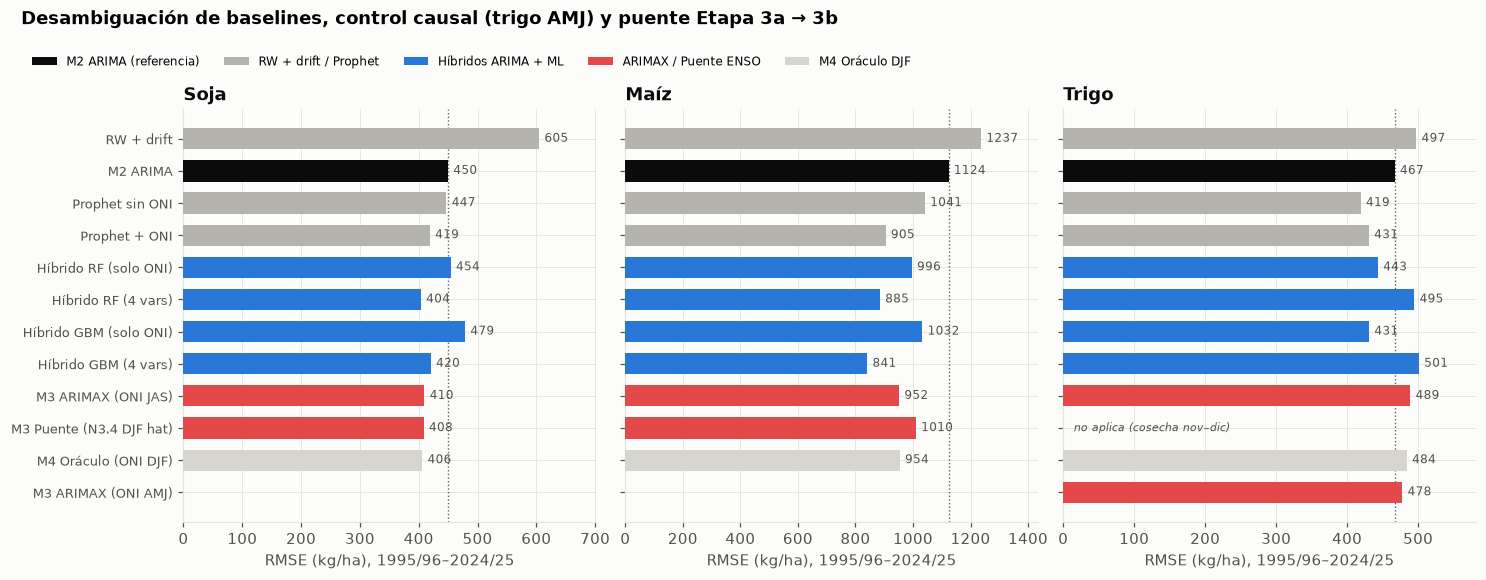

In [7]:
# Figura 18: Desambiguación de baselines + puente 3a->3b
fig, axs = plt.subplots(1, 3, figsize=(13.4, 5.2), sharey=True)
orden_fig18 = [
    ("M0b RW + drift", "RW + drift"),
    ("M2 ARIMA", "M2 ARIMA"),
    ("M5_sin_oni Prophet", "Prophet sin ONI"),
    ("M5 Prophet + ONI", "Prophet + ONI"),
    ("Híbrido RF (solo ONI)", "Híbrido RF (solo ONI)"),
    ("Híbrido RF", "Híbrido RF (4 vars)"),
    ("Híbrido GBM (solo ONI)", "Híbrido GBM (solo ONI)"),
    ("Híbrido GBM", "Híbrido GBM (4 vars)"),
    ("M3 ARIMAX (ONI jul–sep)", "M3 ARIMAX (ONI JAS)"),
    ("M3_puente DJF_hat", "M3 Puente (N3.4 DJF hat)"),
    ("M4 ARIMAX oráculo (ONI dic–feb)", "M4 Oráculo (ONI DJF)"),
    ("M3_trigo_AMJ", "M3 ARIMAX (ONI AMJ)"),
]
y_pos = np.arange(len(orden_fig18))

for ax, c in zip(axs, CULTIVOS):
    p04, pe = pron_04[c], ext_rolling[c]
    obs = p04["obs"]
    rmse_m2 = float(np.sqrt(np.mean((obs - p04["M2 ARIMA"]) ** 2)))
    ax.axvline(rmse_m2, color=COLOR["tinta"], lw=0.9, ls=":", alpha=0.65, zorder=2)

    rmses, cols = [], []
    for key, _ in orden_fig18:
        if key == "M3_trigo_AMJ":
            if c == "trigo":
                sr = df_trigo_amj["M3_trigo_AMJ"]
                rmses.append(float(np.sqrt(np.mean((obs - sr) ** 2))))
            else:
                rmses.append(np.nan)
        elif key == "M3_puente DJF_hat" and c == "trigo":
            rmses.append(np.nan)
        else:
            sr = p04[key] if key in p04.columns else pe[key]
            rmses.append(float(np.sqrt(np.mean((obs - sr) ** 2))))

        if key in ("M3 ARIMAX (ONI jul–sep)", "M3_puente DJF_hat", "M3_trigo_AMJ"):
            cols.append(COLOR["nino"])
        elif "Híbrido" in key:
            cols.append(COLOR["serie"])
        elif "oráculo" in key:
            cols.append("#d6d4ce")
        elif key == "M2 ARIMA":
            cols.append(COLOR["tinta"])
        else:
            cols.append(COLOR["neutral"])

    max_r = float(np.nanmax(rmses))
    valid_idx = [i for i, v in enumerate(rmses) if np.isfinite(v)]
    ax.barh([y_pos[i] for i in valid_idx], [rmses[i] for i in valid_idx],
            color=[cols[i] for i in valid_idx], height=0.66, zorder=3)
    for i, v in enumerate(rmses):
        if np.isfinite(v):
            ax.text(v + max_r * 0.015, i, f"{v:.0f}", va="center", fontsize=7.8, color=COLOR["tinta2"])
    if c == "trigo":
        idx_puente = next(i for i, (k, _) in enumerate(orden_fig18) if k == "M3_puente DJF_hat")
        ax.text(max_r * 0.03, idx_puente, "no aplica (cosecha nov–dic)",
                va="center", fontsize=7.3, style="italic", color=COLOR["tinta2"])
    ax.set_xlim(0, max_r * 1.16)
    ax.set_title(CULTIVO_NOMBRE[c])
    ax.set_xlabel("RMSE (kg/ha), 1995/96–2024/25")

axs[0].set_yticks(y_pos, [lab for _, lab in orden_fig18], fontsize=8.5)
axs[0].invert_yaxis()

legend_handles = [
    Patch(facecolor=COLOR["tinta"], label="M2 ARIMA (referencia)"),
    Patch(facecolor=COLOR["neutral"], label="RW + drift / Prophet"),
    Patch(facecolor=COLOR["serie"], label="Híbridos ARIMA + ML"),
    Patch(facecolor=COLOR["nino"], label="ARIMAX / Puente ENSO"),
    Patch(facecolor="#d6d4ce", label="M4 Oráculo DJF"),
]
fig.get_layout_engine().set(rect=(0.0, 0.0, 1.0, 0.86))
fig.suptitle("Desambiguación de baselines, control causal (trigo AMJ) y puente Etapa 3a → 3b",
             x=0.01, y=0.985, ha="left", va="top", fontweight="bold")
fig.legend(handles=legend_handles, loc="upper left", bbox_to_anchor=(0.01, 0.925),
           ncol=5, fontsize=8, frameon=False)
fig.savefig(FIG / "18_baselines_y_puente_3a_3b.png")
plt.show()

**Lectura e interpretación — Bloque 3:**
- **Trigo causal (`oni_amj`):** al usar el trimestre previo a la siembra de jun–jul tampoco aparece señal ENSO (`RMSE = 477,7` vs `466,9 kg/ha` de `M2 ARIMA`, `p_DM_log = 0,850`), consistente con el contraste exploratorio *(con variabilidad numérica menor entre máquinas por `θ ≈ −1`, sin alterar el resultado nulo)*.
- **Horizonte `h = 2` (`1996–2024`):** al reproducir el salto de 2 campañas de `2026/27` desde `2024/25`, `M3 ARIMAX` retiene `+14,3 %` de skill en soja y `+23,4 %` en maíz con cobertura empírica del `IC95 = 93,1 %`.
- **Puente Etapa 3a → 3b (`ARIMA(2,0,2)`):** se mantiene `ARIMA(2,0,2)` para pronosticar `Niño 3.4 DJF` desde septiembre (`r = 0,909`) en lugar del `MLP` de la Etapa `03`, porque la evaluación rolling de `04` inicia en `1995/96` mientras el `MLP` se entrenó en `1950–1999` (usarlo en `1995–1999` introduciría fuga temporal además de no-determinismo por `early_stopping`). El `M3_puente` logra `+17,6 %` en soja (`p_DM_log = 0,046`) y `+19,2 %` en maíz (`p_DM_log = 0,035`). El **trigo queda excluido** del puente `DJF` porque se cosecha en nov–dic (antes del trimestre pronosticado).

## Bloque 4 — Diagnósticos de Residuos y Diebold-Mariano Unificado + Holm

Completamos los diagnósticos de `04_pronostico_rindes` (ACF/PACF de `Δlog` y Ljung-Box de residuos `M2`/`M3` con `model_df = p + q`)
y unificamos el test de Diebold-Mariano (`kernel="bartlett"` en `utils_ts.dm_test`) tomando **`log(rinde)` como escala primaria**
(fiel a `04`) y **`kg/ha` como sensibilidad**, declarando `M3 vs M2` en soja y maíz como la comparación principal de H3 bajo Holm.

In [8]:
diag_residuos = []
for c in CULTIVOS:
    ly = np.log(Y[c]).reset_index(drop=True)
    orden, r2 = arima_auto(ly)
    p_ord, _, q_ord = orden
    ex_col = "oni_amj" if c == "trigo" else "oni_jas"
    r3 = ajustar_arima(ly, order=orden, exog=X.loc[Y.index, [ex_col]].to_numpy(), trend="t",
                       contexto="B4_diag_M3", cultivo=c, anio=2024)
    for nombre, res in [("M2 ARIMA", r2), (f"M3 ARIMAX ({ex_col})", r3)]:
        e = res.resid.iloc[1:]
        lb = acorr_ljungbox(e, lags=[5, 10], model_df=p_ord + q_ord, return_df=True)
        diag_residuos.append({
            "cultivo": c, "modelo": nombre, "orden": str(orden), "model_df": int(p_ord + q_ord),
            "LB_p_lag5": float(lb.lb_pvalue.iloc[0]),
            "LB_p_lag10": float(lb.lb_pvalue.iloc[1]),
        })
print("Ljung-Box sobre residuos (1970–2024, model_df = p + q):")
print(pd.DataFrame(diag_residuos).round(4).to_string(index=False))

# Tabla maestra DM (log primaria vs kg/ha sensibilidad + Holm en soja y maíz)
todos_modelos = [
    "M0 Naive", "M0b RW + drift", "M1 Tendencia lineal",
    "M3 ARIMAX (ONI jul–sep)", "M3_asim ARIMAX", "M3_puente DJF_hat",
    "M4 ARIMAX oráculo (ONI dic–feb)", "M5_sin_oni Prophet", "M5 Prophet + ONI",
    "Híbrido Ridge", "Híbrido RF (solo ONI)", "Híbrido RF",
    "Híbrido GBM (solo ONI)", "Híbrido GBM", "Híbrido MLP",
]

dm_rows = []
for mdl in todos_modelos:
    fila = {"modelo": mdl}
    for c in CULTIVOS:
        p04, pe = pron_04[c], ext_rolling[c]
        obs, m2 = p04["obs"], p04["M2 ARIMA"]
        if mdl in pe.columns:
            sr = pe[mdl]
        elif mdl in p04.columns:
            sr = p04[mdl]
        else:
            sr = None
        if sr is None:
            fila[f"{c}_DM_log"] = np.nan
            fila[f"{c}_p_log"] = np.nan
            fila[f"{c}_DM_kg"] = np.nan
            fila[f"{c}_p_kg"] = np.nan
        else:
            r_log = dm_test(np.log(obs) - np.log(sr), np.log(obs) - np.log(m2),
                            h=1, alternativa="less", kernel="bartlett")
            r_kg = dm_test(obs - sr, obs - m2, h=1, alternativa="less", kernel="bartlett")
            fila[f"{c}_DM_log"] = float(r_log["DM"])
            fila[f"{c}_p_log"] = float(r_log["p"])
            fila[f"{c}_DM_kg"] = float(r_kg["DM"])
            fila[f"{c}_p_kg"] = float(r_kg["p"])
    # Holm entre los dos cultivos primarios (soja y maiz)
    holm_log = multipletests([fila["soja_p_log"], fila["maiz_p_log"]], method="holm")[1]
    holm_kg = multipletests([fila["soja_p_kg"], fila["maiz_p_kg"]], method="holm")[1]
    fila["soja_pHolm_log"], fila["maiz_pHolm_log"] = float(holm_log[0]), float(holm_log[1])
    fila["soja_pHolm_kg"], fila["maiz_pHolm_kg"] = float(holm_kg[0]), float(holm_kg[1])
    dm_rows.append(fila)

dm_master = pd.DataFrame(dm_rows)
cols_show = ["modelo", "soja_p_log", "soja_pHolm_log", "soja_p_kg", "soja_pHolm_kg",
             "maiz_p_log", "maiz_pHolm_log", "maiz_p_kg", "maiz_pHolm_kg", "trigo_p_log"]
print("\nTabla maestra Diebold-Mariano (unilateral less vs M2 ARIMA; primaria log + sens. kg/ha + Holm en soja/maíz):")
print(dm_master[cols_show].round(4).to_string(index=False))

ext_results["bloque4_diagnosticos_ljungbox"] = pd.DataFrame(diag_residuos).round(4).to_dict("records")
ext_results["bloque4_dm_unificado_holm"] = dm_master.round(4).to_dict("records")

Ljung-Box sobre residuos (1970–2024, model_df = p + q):
cultivo              modelo     orden  model_df  LB_p_lag5  LB_p_lag10
   soja            M2 ARIMA (0, 1, 1)         1     0.8956      0.9162
   soja M3 ARIMAX (oni_jas) (0, 1, 1)         1     0.7547      0.8051
   maiz            M2 ARIMA (0, 1, 1)         1     0.3803      0.8245
   maiz M3 ARIMAX (oni_jas) (0, 1, 1)         1     0.1220      0.1214
  trigo            M2 ARIMA (0, 1, 1)         1     0.6915      0.8099
  trigo M3 ARIMAX (oni_amj) (0, 1, 1)         1     0.7645      0.8238



Tabla maestra Diebold-Mariano (unilateral less vs M2 ARIMA; primaria log + sens. kg/ha + Holm en soja/maíz):
                         modelo  soja_p_log  soja_pHolm_log  soja_p_kg  soja_pHolm_kg  maiz_p_log  maiz_pHolm_log  maiz_p_kg  maiz_pHolm_kg  trigo_p_log
                       M0 Naive      0.9442          1.0000     0.9454         1.0000      0.7143          1.0000     0.6772         1.0000       0.7422
                 M0b RW + drift      0.9552          1.0000     0.9597         1.0000      0.7562          1.0000     0.7495         1.0000       0.7787
            M1 Tendencia lineal      0.1656          0.3312     0.1662         0.3324      0.9792          0.9792     0.9850         0.9850       0.2004
        M3 ARIMAX (ONI jul–sep)      0.0970          0.0970     0.1150         0.1150      0.0433          0.0865     0.0251         0.0502       0.7655
                 M3_asim ARIMAX      0.2413          0.2520     0.2056         0.2056      0.1260          0.2520     0.0422 

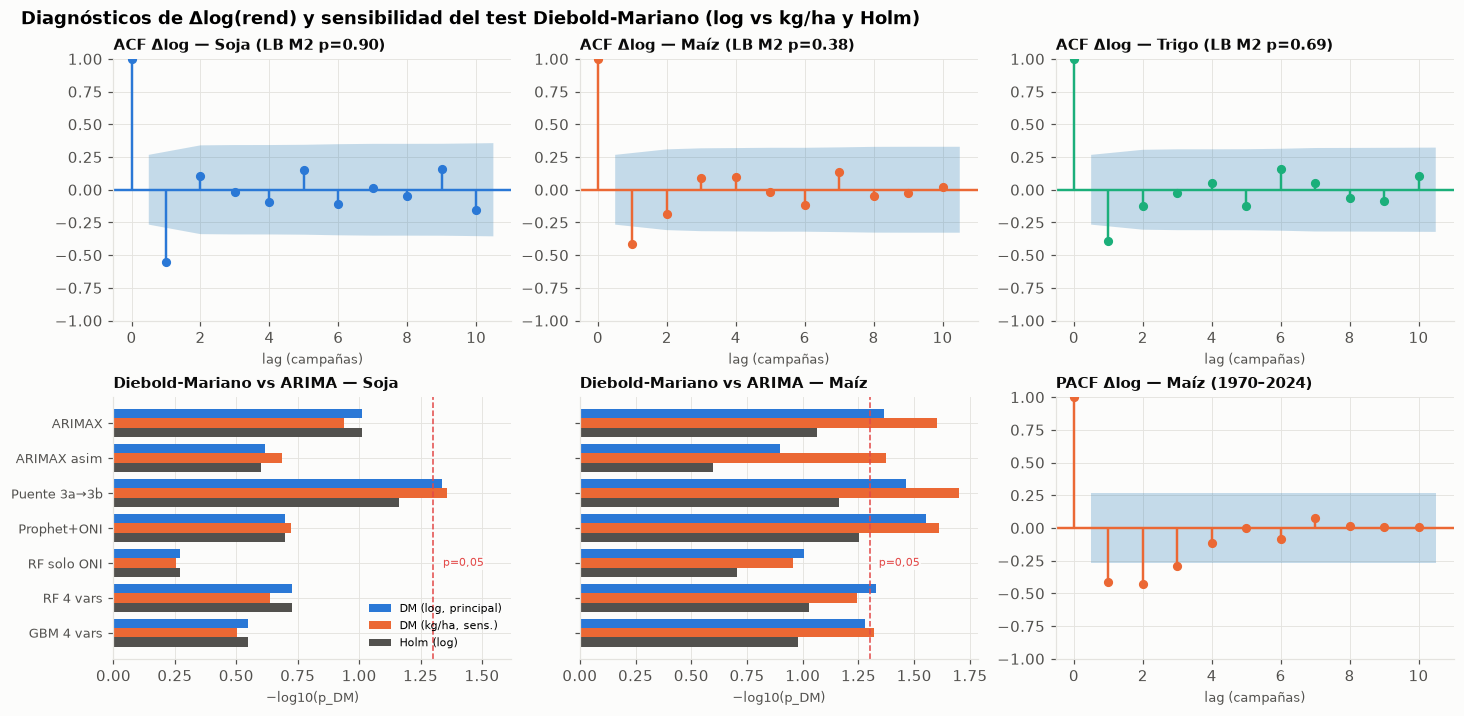

In [9]:
# Figura 19: ACF/PACF de Δlog + comparación p_DM (log vs kg/ha y Holm)
fig, axs = plt.subplots(2, 3, figsize=(13.2, 6.4))

for j, c in enumerate(CULTIVOS):
    ax = axs[0, j]
    dlog = np.log(Y[c]).diff().dropna()
    plot_acf(dlog, lags=10, ax=ax, color=CULTIVO_COLOR[c], vlines_kwargs={"colors": CULTIVO_COLOR[c]}, title="")
    ax.set_title(f"ACF Δlog — {CULTIVO_NOMBRE[c]} (LB M2 p={diag_residuos[2*j]['LB_p_lag5']:.2f})", fontsize=9.5)
    ax.set_xlabel("lag (campañas)", fontsize=8.5)

ax_soja, ax_maiz, ax_pacf = axs[1, 0], axs[1, 1], axs[1, 2]

# PACF de Δlog maíz (cultivo clave con quiebre de tendencia)
plot_pacf(np.log(Y["maiz"]).diff().dropna(), lags=10, method="ywm", ax=ax_pacf,
          color=CULTIVO_COLOR["maiz"], vlines_kwargs={"colors": CULTIVO_COLOR["maiz"]}, title="")
ax_pacf.set_title("PACF Δlog — Maíz (1970–2024)", fontsize=9.5)
ax_pacf.set_xlabel("lag (campañas)", fontsize=8.5)

sel_dm = ["M3 ARIMAX (ONI jul–sep)", "M3_asim ARIMAX", "M3_puente DJF_hat",
          "M5 Prophet + ONI", "Híbrido RF (solo ONI)", "Híbrido RF", "Híbrido GBM"]
short_dm = ["ARIMAX", "ARIMAX asim", "Puente 3a→3b", "Prophet+ONI", "RF solo ONI", "RF 4 vars", "GBM 4 vars"]
sub_dm = dm_master.set_index("modelo").loc[sel_dm]
y_idx = np.arange(len(sel_dm))
h_bar = 0.27
for ax, c in [(ax_soja, "soja"), (ax_maiz, "maiz")]:
    ax.barh(y_idx - h_bar, -np.log10(sub_dm[f"{c}_p_log"]), height=h_bar, color=COLOR["serie"], label="DM (log, principal)")
    ax.barh(y_idx, -np.log10(sub_dm[f"{c}_p_kg"]), height=h_bar, color=COLOR["tendencia"], label="DM (kg/ha, sens.)")
    ax.barh(y_idx + h_bar, -np.log10(sub_dm[f"{c}_pHolm_log"]), height=h_bar, color=COLOR["tinta2"], label="Holm (log)")
    ax.axvline(-np.log10(0.05), color=COLOR["nino"], lw=1, ls="--")
    ax.set_xlim(0, max(1.62, ax.get_xlim()[1]))
    ax.text(-np.log10(0.05) + 0.04, 4.0, "p=0,05", va="center", fontsize=7.5, color=COLOR["nino"],
            bbox=dict(facecolor=COLOR["fondo"], alpha=0.85, edgecolor="none", pad=1))
    ax.set_yticks(y_idx, short_dm if c == "soja" else [""] * len(short_dm), fontsize=8.5)
    ax.invert_yaxis()
    ax.set_xlabel("−log10(p_DM)", fontsize=8.5)
    ax.set_title(f"Diebold-Mariano vs ARIMA — {CULTIVO_NOMBRE[c]}", fontsize=9.5)
ax_soja.legend(fontsize=7.2, loc="lower right")
fig.suptitle("Diagnósticos de Δlog(rend) y sensibilidad del test Diebold-Mariano (log vs kg/ha y Holm)",
             x=0.01, ha="left", fontweight="bold")
fig.savefig(FIG / "19_diagnosticos_y_dm.png")
plt.show()

**Lectura e interpretación — Bloque 4:**
- **Residuos (`model_df = p + q`):** descontando los grados de libertad de `ARIMA(0,1,1)` (`model_df = 1`), Ljung-Box (`lags = 5, 10`) **no rechaza ruido blanco** en ningún cultivo para `M2` ni `M3`.
- **Comparación primaria (`M3 vs M2` en `log`) vs sensibilidad (`kg/ha`):** siguiendo la escala de la Etapa `04`, en `log` bajo corrección de Holm entre soja y maíz el `M3 ARIMAX` queda en zona marginal (`maíz p_Holm = 0,0865`, `soja p_Holm = 0,0970`), mientras en sensibilidad `kg/ha` `M3` da `0,0502` en maíz y `M3_puente` alcanza significancia (`maíz 0,0399`, `soja 0,0437`). Los restantes modelos son exploratorios; H3 queda **parcialmente sostenida**.

## Bloque 5 — Coherencia Wavelet (`Niño 3.4` ↔ `precip_z` pampeana, `1981–2025`, `n = 540`)

Implementación según **Grinsted, Moore & Jevrejeva (2004)** con wavelet Morlet (`ω₀ = 6`):
- Suavizado gaussiano en el tiempo (escala-dependiente) y rectángulo (*boxcar*) de ancho `0,60` octavas en escala.
- Cono de influencia (COI), flechas de fase donde `R² > 0,5` y significancia al 95 % por **250 simulaciones Monte Carlo AR(1)**.

In [10]:
m_wc = pd.concat([enso["n34_anom"], clima["precip_z"]], axis=1).loc["1981":"2025"].dropna()
xw = (m_wc["n34_anom"].to_numpy(float) - m_wc["n34_anom"].mean()) / m_wc["n34_anom"].std()
yw = (m_wc["precip_z"].to_numpy(float) - m_wc["precip_z"].mean()) / m_wc["precip_z"].std()

N_w = len(xw)
grilla = grilla_morlet(n=N_w, dt=1.0 / 12.0, dj=1.0 / 12.0, omega0=6.0)
scales = grilla["scales"]
periods = grilla["periods"]
coi_period = grilla["coi_period"]
inside_coi = grilla["inside_coi"]

R2_obs, phase_obs, _ = wavelet_coherence(xw, yw, grilla=grilla)
assert np.all((R2_obs >= 0.0) & (R2_obs <= 1.0)), "R² fuera de [0, 1]!"
assert float(R2_obs.mean()) < 0.99, "R² degenerado cerca de 1!"

# Significancia Monte Carlo AR(1) (pares independientes vectorizados; ENSO_N_MC=250 por defecto)
t_mc = time.time()
phi_x = float(m_wc["n34_anom"].autocorr(1))
phi_y = float(m_wc["precip_z"].autocorr(1))
sig95_scale, n_mc = umbral_montecarlo_ar1(phi_x, phi_y, grilla=grilla, batch_mc=25, burn=100, borde=60, seed=0)
sig95_ratio = R2_obs / sig95_scale[:, None]
print(f"Coherencia wavelet + MC AR(1) ({n_mc} sims) lista en {time.time() - t_mc:.1f} s · "
      f"R² min={R2_obs.min():.3f}, mean={R2_obs.mean():.3f}, max={R2_obs.max():.3f}", flush=True)

# COI, indicadores por década y media circular de fase en la zona significativa (2–7 años dentro de COI)
band_enso = (periods >= 2.0) & (periods <= 7.0)
sig_banda = (sig95_ratio >= 1.0) & inside_coi & band_enso[:, None]
fase_raw = fase_circular_media(phase_obs, sig_banda)
fase_media_rad = fase_raw["fase_media_rad"]
fase_media_grados = fase_raw["fase_media_grados"]
R_resultante = fase_raw["longitud_resultante_R"]
disp_circular = fase_raw["dispersion_circular"]
fase_stats = {
    "n_celdas_sig_2_7": fase_raw["n_celdas"],
    "fase_media_rad": fase_media_rad,
    "fase_media_grados": fase_media_grados,
    "longitud_resultante_R": R_resultante,
    "dispersion_circular": disp_circular,
}
print(
    f"Fase media circular (COI, 2–7 años, sig ≥ 95 %, n={fase_stats['n_celdas_sig_2_7']}): "
    f"{fase_media_rad:+.3f} rad ({fase_media_grados:+.1f}°), R = {R_resultante:.3f}, dispersión (1 − R) = {disp_circular:.3f}"
)

decadas = [("1980s (1981–89)", 1981, 1989), ("1990s (1990–99)", 1990, 1999),
           ("2000s (2000–09)", 2000, 2009), ("2010s–2020s (2010–25)", 2010, 2025)]
coh_decadas = []
years_w = m_wc.index.year.to_numpy()
for nombre_d, y0, y1 in decadas:
    mask_t = (years_w >= y0) & (years_w <= y1)
    sub_mask = band_enso[:, None] & inside_coi & mask_t[None, :]
    r2_sub = R2_obs[sub_mask]
    sig_mask_d = (sig95_ratio >= 1.0) & sub_mask
    sig_sub = (sig95_ratio >= 1.0)[sub_mask]
    fase_d = fase_circular_media(phase_obs, sig_mask_d)
    coh_decadas.append({
        "decada": nombre_d,
        "n_celdas_COI": int(sub_mask.sum()),
        "R2_media_2_7_anios": float(r2_sub.mean()),
        "R2_max_2_7_anios": float(r2_sub.max()),
        "frac_sig95_%": float(100.0 * sig_sub.mean()),
        "fase_media_grados": fase_d["fase_media_grados"],
        "R_resultante": fase_d["longitud_resultante_R"],
    })
print("\nCoherencia wavelet media (2–7 años, dentro del COI) por década:")
print(pd.DataFrame(coh_decadas).round(3).to_string(index=False))

ext_results["bloque5_coherencia_wavelet"] = {
    "n_meses": N_w,
    "ar1_nino34": phi_x,
    "ar1_precip_z": phi_y,
    "n_mc": n_mc,
    "R2_global_mean": float(R2_obs.mean()),
    "R2_global_max": float(R2_obs.max()),
    "fase_media_sig_2_7": fase_stats,
    "decadas": coh_decadas,
}

Coherencia wavelet + MC AR(1) (250 sims) lista en 6.3 s · R² min=0.000, mean=0.477, max=0.968


Fase media circular (COI, 2–7 años, sig ≥ 95 %, n=1649): +0.174 rad (+10.0°), R = 0.875, dispersión (1 − R) = 0.125

Coherencia wavelet media (2–7 años, dentro del COI) por década:
               decada  n_celdas_COI  R2_media_2_7_anios  R2_max_2_7_anios  frac_sig95_%  fase_media_grados  R_resultante
      1980s (1981–89)           919               0.463             0.711         0.000                NaN           NaN
      1990s (1990–99)          2634               0.474             0.895        23.652            -19.663         0.899
      2000s (2000–09)          2640               0.534             0.968        35.985             27.251         0.979
2010s–2020s (2010–25)          2761               0.341             0.826         2.753             10.401         0.896


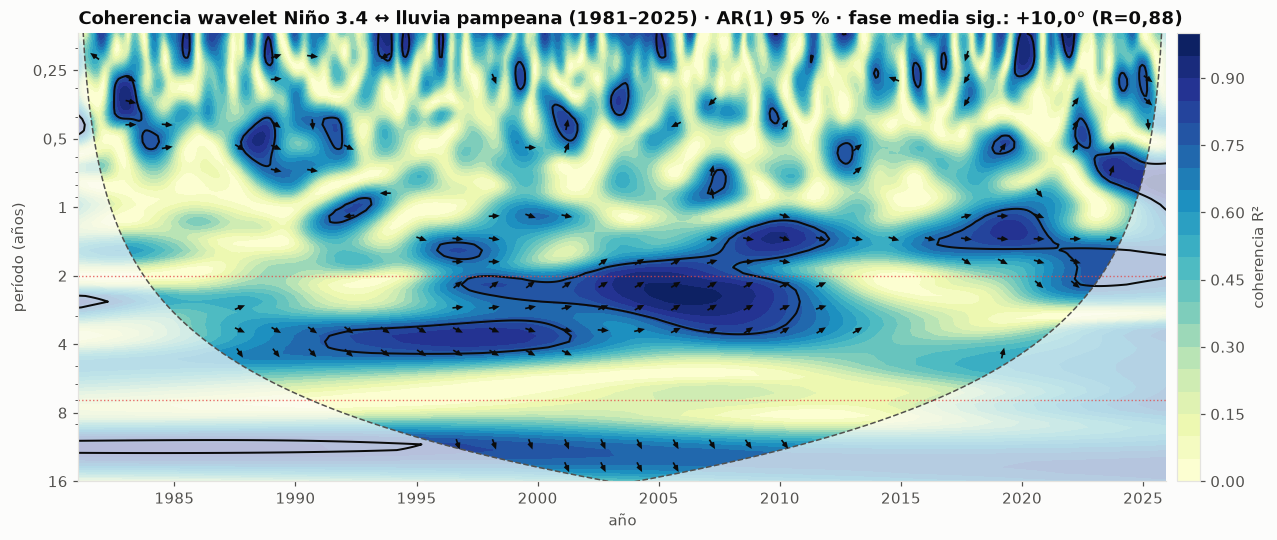

In [11]:
# Figura 20: Mapa tiempo-período de coherencia wavelet
anios_ax = m_wc.index.year + (m_wc.index.month - 0.5) / 12.0
fig, ax = plt.subplots(figsize=(11.5, 4.8))
im = ax.contourf(anios_ax, periods, R2_obs, levels=np.linspace(0, 1, 21), cmap="YlGnBu")
ax.contour(anios_ax, periods, sig95_ratio, levels=[1.0], colors=[COLOR["tinta"]], linewidths=1.3)
ax.fill_between(anios_ax, coi_period, periods.max(), color=COLOR["fondo"], alpha=0.68, lw=0)
ax.plot(anios_ax, coi_period, color=COLOR["tinta2"], lw=1.0, ls="--")

# Flechas de fase donde R² > 0.5 y dentro de COI
step_t, step_s = 18, 4
tt_idx = np.arange(8, N_w, step_t)
ss_idx = np.arange(4, len(periods) - 2, step_s)
TT, SS = np.meshgrid(tt_idx, ss_idx)
mask_arr = (R2_obs[SS, TT] > 0.5) & (periods[SS] <= coi_period[TT])
U = np.cos(phase_obs[SS, TT]) * mask_arr
V = np.sin(phase_obs[SS, TT]) * mask_arr
if mask_arr.any():
    ax.quiver(anios_ax[TT[mask_arr]], periods[SS[mask_arr]], U[mask_arr], V[mask_arr],
              units="inches", scale=10, width=0.015, headwidth=3.5, headlength=4.0,
              color=COLOR["tinta"], pivot="mid", zorder=4)

for b_p in (2.0, 7.0):
    ax.axhline(b_p, color=COLOR["nino"], lw=0.9, ls=":", alpha=0.8)
ax.set_yscale("log")
ax.set_yticks([0.25, 0.5, 1, 2, 4, 8, 16], ["0,25", "0,5", "1", "2", "4", "8", "16"])
ax.set_ylim(min(16.0, periods.max()), periods.min())
ax.set_ylabel("período (años)")
ax.set_xlabel("año")
fase_txt = f"{fase_media_grados:+.1f}° (R={R_resultante:.2f})".replace(".", ",")
ax.set_title(
    f"Coherencia wavelet Niño 3.4 ↔ lluvia pampeana (1981–2025) · AR(1) 95 % · fase media sig.: {fase_txt}"
)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.01)
cb.set_label("coherencia R²")
fig.savefig(FIG / "20_coherencia_wavelet.png")
plt.show()

**Lectura e interpretación — Bloque 5:**
- **Test celda por celda vs azar:** el contorno al 95 % espera ~5 % de área significativa por mero azar bajo AR(1). En `1990–1999` (`23,7 %`) y `2000–2009` (`36,0 %`) emerge un acople claro muy por encima del umbral aleatorio, mientras que en los `1980s` (`0,0 %`) y `2010–2025` (`2,8 % < 5 %`) **no aparece coherencia significativa** (no es simplemente un debilitamiento gradual sino ausencia de señal respecto al ruido rojo).
- **Fase circular media en zona significativa:** sobre las celdas con `sig95_ratio ≥ 1` dentro del COI en `2–7` años, las series se mantienen acopladas cerca de fase positiva (media circular en radianes/grados y longitud resultante `R` impresas arriba y guardadas en `results/etapa4_extensiones.json`).

## Exportación de resultados consolidados (`results/etapa4_extensiones.json` y CSV)

In [12]:
n_cw = sum(1 for r in CONV_LOG if r["conv_warning"])
n_bnd = sum(1 for r in CONV_LOG if r["cerca_borde_MA"])
print(f"Resumen convergencia ARIMA/ARIMAX: {n_cw} ConvergenceWarning(s), {n_bnd} ajustes con |MA| ≈ 1 (detalle en JSON)")
ext_results["bloque1_convergencia_arima"] = {
    "n_convergence_warnings": n_cw,
    "n_ma_cerca_borde": n_bnd,
    "por_contexto": pd.DataFrame(CONV_LOG).groupby(["contexto", "cultivo"], dropna=False).agg(
        n_conv=("conv_warning", "sum"), n_borde=("cerca_borde_MA", "sum")
    ).reset_index().to_dict("records") if CONV_LOG else [],
    "detalle": CONV_LOG,
}

df_rolling_ext = pd.concat([df.assign(cultivo=c).reset_index() for c, df in ext_rolling.items()], ignore_index=True)
df_rolling_ext = df_rolling_ext.merge(df_trigo_amj.reset_index().assign(cultivo="trigo"), on=["cultivo", "campania"], how="left")
df_rolling_ext.to_csv(RES / "pronosticos_rolling_extensiones.csv", index=False)
(RES / "etapa4_extensiones.json").write_text(json.dumps(ext_results, indent=2, default=float, ensure_ascii=False), encoding="utf-8")
print("Guardado results/etapa4_extensiones.json y results/pronosticos_rolling_extensiones.csv", flush=True)

Resumen convergencia ARIMA/ARIMAX: 48 ConvergenceWarning(s), 251 ajustes con |MA| ≈ 1 (detalle en JSON)
Guardado results/etapa4_extensiones.json y results/pronosticos_rolling_extensiones.csv
